# ML — Unsupervised Learning
### Data Science Core Concepts 101 — by Yunhan Jin

Unsupervised learning finds structure in data **without labels**. There is no target variable — the algorithm discovers patterns on its own.

Two main applications:
- **Clustering**: group similar data points together — e.g. customer segments, topic clusters
- **Dimensionality reduction**: compress many features into fewer — e.g. visualizing high-dimensional data, reducing noise before modeling

---

## Section 1: Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n = 500
neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs', 'Riverside'] * (n // 5)
conditions = ['Poor', 'Fair', 'Good', 'Excellent']

df = pd.DataFrame({
    'sqft':         np.random.normal(1800, 400, n).astype(int).clip(600, 4000),
    'bedrooms':     np.random.choice([2, 3, 4, 5], n, p=[0.2, 0.4, 0.3, 0.1]),
    'neighborhood': neighborhoods,
    'condition':    np.random.choice(conditions, n, p=[0.1, 0.2, 0.5, 0.2]),
    'year_built':   np.random.randint(1960, 2020, n),
    'has_garage':   np.random.choice([True, False], n, p=[0.7, 0.3]),
})

hood_price = {'Downtown': 1.3, 'Midtown': 1.1, 'Uptown': 1.0, 'Suburbs': 0.9, 'Riverside': 1.05}
cond_price  = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}

df['price'] = (
    80000
    + df['sqft'] * 120
    + df['bedrooms'] * 8000
    + df['condition'].map(cond_price) * 15000
    + df['has_garage'].astype(int) * 12000
    + np.random.normal(0, 20000, n)
) * df['neighborhood'].map(hood_price)
df['price']             = df['price'].clip(100000, 1000000).astype(int)
df['condition_encoded'] = df['condition'].map({'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3})
df['has_garage']        = df['has_garage'].astype(int)
df['house_age']         = 2024 - df['year_built']

# Numeric features for clustering and PCA
feature_cols = ['sqft', 'bedrooms', 'condition_encoded', 'has_garage', 'house_age', 'price']
X = df[feature_cols].copy()

# Scale — required for K-Means and PCA (distance/variance sensitive)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Dataset shape: {X.shape}')
X.describe().round(1)

Dataset shape: (500, 6)


,sqft,bedrooms,condition_encoded,has_garage,house_age,price
count,500.0,500.0,500.0,500.0,500.0,500.0
mean,1802.4,3.3,1.8,0.7,35.0,383636.7
std,391.9,0.9,0.9,0.5,17.0,72873.7
min,600.0,2.0,0.0,0.0,5.0,211891.0
25%,1519.8,3.0,1.0,0.0,21.0,331140.8
50%,1805.0,3.0,2.0,1.0,36.0,375245.0
75%,2054.2,4.0,2.0,1.0,49.0,431754.2
max,3341.0,5.0,3.0,1.0,64.0,601896.0


---
## Section 2: K-Means Clustering
K-Means partitions data into **k clusters** by minimizing the sum of squared distances from each point to its cluster centroid. You specify k upfront.

**How it works:**
1. Randomly initialize k centroids
2. Assign each point to the nearest centroid
3. Recompute centroids as the mean of each cluster
4. Repeat until centroids stop moving

### 2.1 Elbow Method
Plot **inertia** (total within-cluster sum of squares) vs k. Look for the "elbow" where adding more clusters gives diminishing returns.

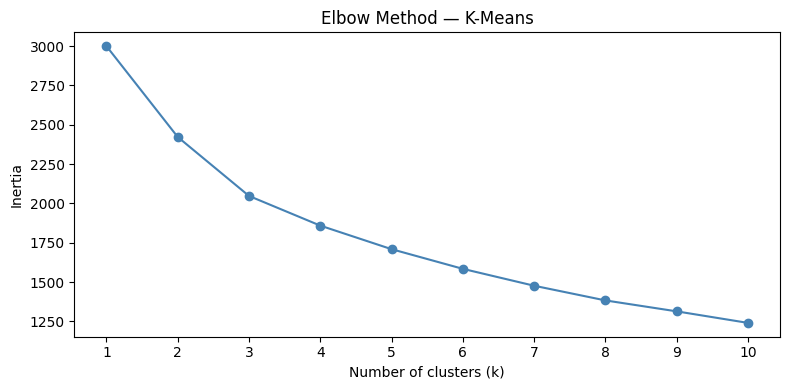

In [2]:
inertias = []
k_range  = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, marker='o', color='steelblue')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method — K-Means')
plt.xticks(k_range)
plt.tight_layout()
plt.show()

### 2.2 Fit K-Means
Based on the elbow, we use k=4.

In [3]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = km.fit_predict(X_scaled)

print('Cluster sizes:')
print(df['cluster'].value_counts().sort_index())

print('\nCluster means (original scale):')
print(df.groupby('cluster')[feature_cols].mean().round(0))

Cluster sizes:
cluster
0    133
1    143
2    130
3     94
Name: count, dtype: int64

Cluster means (original scale):
           sqft  bedrooms  condition_encoded  has_garage  house_age     price
cluster                                                                      
0        2195.0       3.0                2.0         1.0       38.0  467647.0
1        1592.0       3.0                2.0         1.0       34.0  353302.0
2        1712.0       3.0                2.0         0.0       32.0  363191.0
3        1692.0       3.0                0.0         1.0       37.0  339194.0


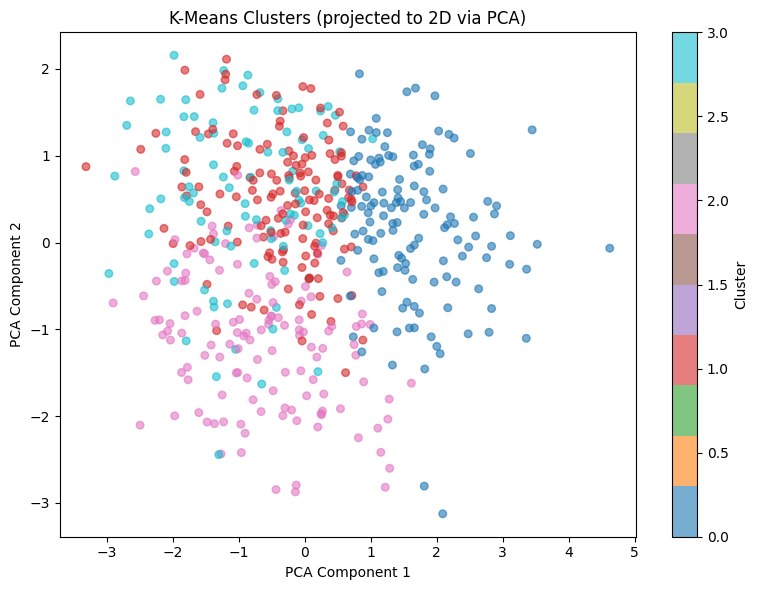

In [4]:
# Visualize clusters — project to 2D with PCA for plotting
pca_2d  = PCA(n_components=2)
X_2d    = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df['cluster'], cmap='tab10', alpha=0.6, s=30)
plt.colorbar(scatter, label='Cluster')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('K-Means Clusters (projected to 2D via PCA)')
plt.tight_layout()
plt.show()

---
## Section 3: DBSCAN
**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) groups points that are densely packed together. Unlike K-Means:
- You don't specify k upfront
- It handles **arbitrary cluster shapes**
- Points in sparse regions are labeled **noise** (label = -1)

Key parameters:
- `eps`: radius of the neighborhood around each point
- `min_samples`: minimum points within `eps` to form a core point

Clusters found: 1
Noise points:   102


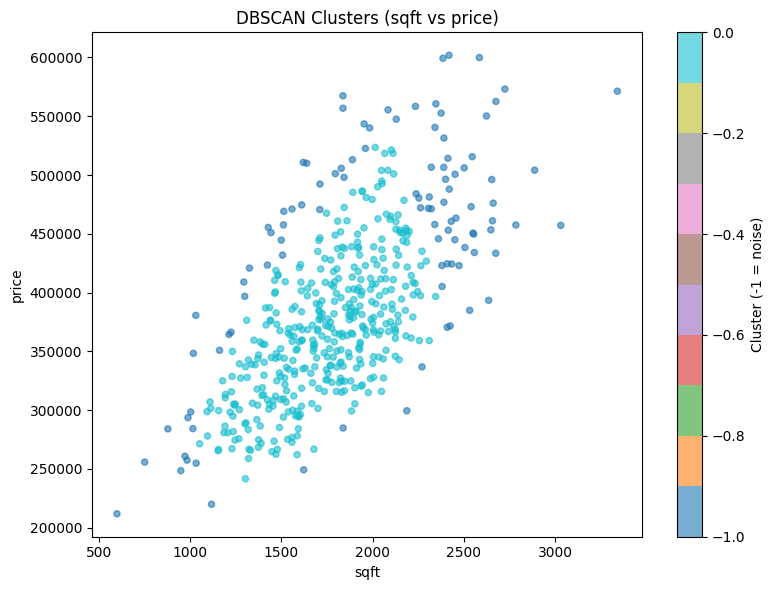

In [5]:
# Use sqft and price (scaled) for a clear 2D visualization
X_2feat = scaler.fit_transform(df[['sqft', 'price']])

db = DBSCAN(eps=0.3, min_samples=10)
db_labels = db.fit_predict(X_2feat)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise    = (db_labels == -1).sum()
print(f'Clusters found: {n_clusters}')
print(f'Noise points:   {n_noise}')

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['sqft'], df['price'],
    c=db_labels, cmap='tab10', alpha=0.6, s=20
)
plt.colorbar(scatter, label='Cluster (-1 = noise)')
plt.xlabel('sqft')
plt.ylabel('price')
plt.title('DBSCAN Clusters (sqft vs price)')
plt.tight_layout()
plt.show()

---
## Section 4: PCA — Dimensionality Reduction
**PCA** (Principal Component Analysis) transforms features into a new set of uncorrelated axes (principal components) ordered by the variance they explain. Used to:
- Visualize high-dimensional data in 2D/3D
- Remove redundant/noisy features before modeling
- Speed up training on large feature sets

### 4.1 Explained Variance (Scree Plot)
Each principal component explains a fraction of the total variance. The scree plot shows how many components are needed to capture most of the variance.

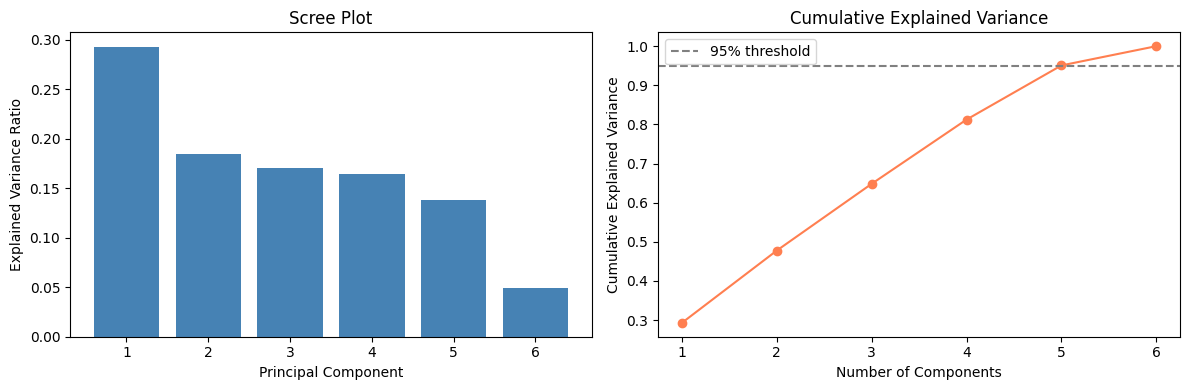

PC1: 0.293 | Cumulative: 0.293
PC2: 0.185 | Cumulative: 0.478
PC3: 0.171 | Cumulative: 0.648
PC4: 0.164 | Cumulative: 0.812
PC5: 0.138 | Cumulative: 0.951
PC6: 0.049 | Cumulative: 1.000


In [6]:
pca_full = PCA()
pca_full.fit(X_scaled)

explained   = pca_full.explained_variance_ratio_
cumulative  = np.cumsum(explained)
n_features  = len(explained)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(1, n_features + 1), explained, color='steelblue')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot')
axes[0].set_xticks(range(1, n_features + 1))

axes[1].plot(range(1, n_features + 1), cumulative, marker='o', color='coral')
axes[1].axhline(0.95, linestyle='--', color='gray', label='95% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xticks(range(1, n_features + 1))
axes[1].legend()

plt.tight_layout()
plt.show()

for i, (ev, cv) in enumerate(zip(explained, cumulative)):
    print(f'PC{i+1}: {ev:.3f} | Cumulative: {cv:.3f}')

### 4.2 2D Visualization
Project data onto the first 2 principal components and color by neighborhood — not used in PCA training, just as external validation to see if the components capture meaningful structure.

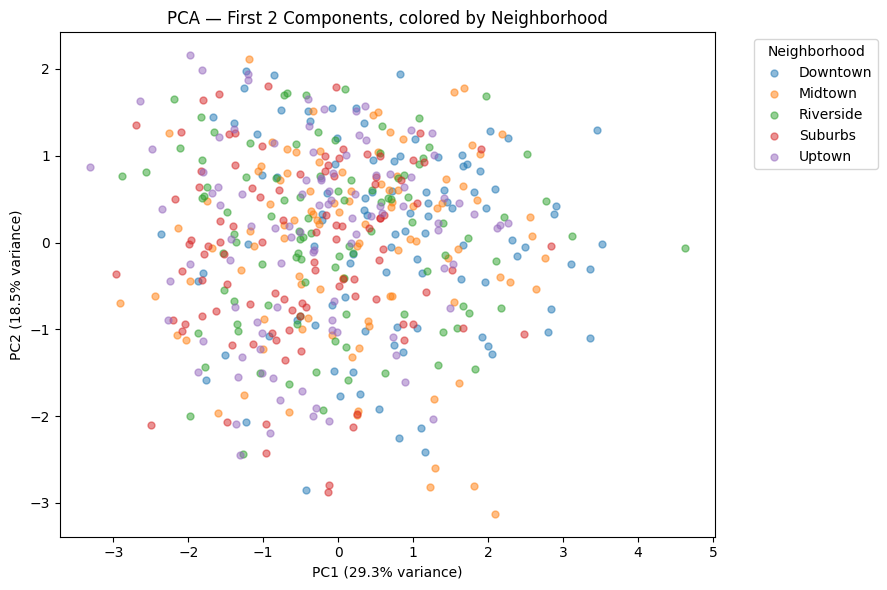

Component loadings:
                     PC1    PC2
sqft               0.644 -0.096
bedrooms           0.078 -0.449
condition_encoded  0.196 -0.131
has_garage         0.252  0.650
house_age          0.023  0.586
price              0.691 -0.080


In [7]:
pca_2 = PCA(n_components=2)
X_pca = pca_2.fit_transform(X_scaled)

neighborhoods_orig = ['Downtown', 'Midtown', 'Uptown', 'Suburbs', 'Riverside'] * (n // 5)
hood_labels        = pd.Categorical(neighborhoods_orig)

plt.figure(figsize=(9, 6))
for hood in hood_labels.categories:
    mask = np.array(neighborhoods_orig) == hood
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=hood, alpha=0.5, s=25)

plt.xlabel(f'PC1 ({pca_2.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca_2.explained_variance_ratio_[1]:.1%} variance)')
plt.title('PCA — First 2 Components, colored by Neighborhood')
plt.legend(title='Neighborhood', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Component loadings — how much each feature contributes to PC1 and PC2
loadings = pd.DataFrame(
    pca_2.components_.T,
    index=feature_cols,
    columns=['PC1', 'PC2']
).round(3)
print('Component loadings:')
print(loadings)

---
## Section 5: Common Mistakes
- **Forgetting to scale**: K-Means and PCA are distance/variance sensitive. Features on larger scales dominate — always scale first.
- **Choosing k arbitrarily**: use the elbow method or silhouette score to guide the choice — don't just pick a round number.
- **Over-interpreting clusters**: cluster labels have no inherent meaning. Always inspect cluster means and distributions to understand what a cluster represents.
- **Assuming PCA always improves models**: PCA reduces dimensions but discards variance. If the discarded components contain signal, model performance may drop. Validate on held-out data.